# P07 — Benchmark de métodos de integração (no estilo do scIB)

**Pergunta.** Que método de integração usar no objeto principal, e por quê?
O P05 integrou com o Harmony por biblioteca, como o processamento original.
Aqui essa escolha é posta contra os métodos do benchmark de Luecken et al.
(2022), *Benchmarking atlas-level data integration in single-cell genomics*,
Nat Methods 19:41–50 (o "scIB"). As métricas, a agregação e as figuras são as
do artigo.

**O que vem do artigo**

* os métodos disponíveis em versão mantida: Harmony, Scanorama (embedding e
  matriz corrigida), BBKNN, ComBat, scVI, scANVI, scGen, Seurat (CCA e RPCA),
  além do não integrado;
* a preparação: 2.000 genes variáveis escolhidos por biblioteca (os do P05),
  com e sem escala quando o método aceita as duas — o artigo achou que a
  escala melhora a remoção de lote e piora a conservação biológica;
* as métricas, calculadas com o pacote do artigo (`scib` 1.1.7): 5 de
  remoção de lote (PCR batch, batch ASW, graph iLISI, graph connectivity,
  kBET) e 8 de conservação biológica (NMI e ARI, cell type ASW, isolated
  label F1 e silhouette, graph cLISI, ciclo celular, conservação de HVG);
* a agregação: cada métrica escalonada (min-max) entre as execuções; média
  por grupo; score geral = 0,4 × lote + 0,6 × bio;
* as figuras: tabela-resumo (Figs. 2a e 3b), lote × bio (Fig. 3a e
  Extended Data Fig. 4), UMAPs (Fig. 2b–c), tempo e memória (Extended Data
  Fig. 7).

**O que muda, e por quê** (decisões de 20/10/2026)

* **Rótulo.** O artigo usa anotação curada; aqui não há anotação. As
  métricas biológicas usam o Azimuth que o Cell Ranger rodou em cada
  biblioteca, agrupado em 7 classes — ele não depende da integração. As
  células sem Azimuth (fora da chamada do Cell Ranger) ou sem rótulo confiável
  entram na integração, mas não nas métricas.
* **Lote = biblioteca** (14), como no P05. Como o estímulo está confundido com
  a biblioteca, toda correção por biblioteca tende a apagar a resposta ao
  *M. leprae*. Por isso entra uma **métrica do estudo**, fora do score do
  artigo: a fração da separação NS × ML dentro do paciente que cada método
  preserva, em relação ao não integrado. Ela serve de veto e de desempate.
* **scANVI e scGen** usam o rótulo no treino, e o mesmo rótulo é usado na
  avaliação (o artigo os marca com asterisco). Aparecem na tabela, mas **não
  são elegíveis**: o rótulo é automático e seria imposto ao espaço latente.
* **Ausentes:** FastMNN e LIGER (fora do escopo combinado), MNN (o `mnnpy` não
  tem manutenção), Conos (R, não instalado no ambiente isolado), DESC,
  SAUCIE e trVAE (sem versão compatível com Python 3.11 / scvi-tools 1.x; no
  artigo, os três ficaram entre os piores).
* **kBET.** No `scib` ele chama o pacote R kBET via rpy2. Aqui é um porte do
  mesmo procedimento (`functions/benchmark.py`), validado na seção 3.
* **Uma tarefa só.** O artigo agrega 13 tarefas e mostra barras de erro entre
  elas; aqui há um conjunto de dados. A robustez da escolha é medida mudando
  a agregação (seção 9).

**Regra de escolha** (fixada antes de ver os resultados, em `benchmark.choose`):

1. elegíveis: os métodos que não usam rótulo, fora o não integrado;
2. veto: preservar menos estímulo que a integração atual (Harmony do P05)
   por mais de 10 pontos percentuais da separação do não integrado;
3. entre os não vetados, quem fica a menos de 0,02 do maior score geral
   empata; no empate, vence quem preserva mais estímulo.

**Execução.** Os ajustes e as métricas rodam fora do notebook
(`raw/run_benchmark.py tudo`), um processo por método, com cache no NVMe
(`HEAVY_OUT/P07_benchmark_integracao/`). Este notebook só lê o cache.

Limite de inferência: 7 pacientes, 14 bibliotecas; MB e NP com um paciente
cada. O benchmark compara métodos sobre as mesmas células; não testa
hipótese biológica.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import json
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from scipy import stats

from functions import benchmark as bm, benchplots as bp, config, fmt as F, io, pipeline as pl, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = bm.STAGE
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK

## 1. As células e o rótulo

As entradas são as do cache (`raw/run_benchmark.py entradas`): as 35.247
células do objeto principal, com as 2.000 HVG do P05. O rótulo é o Azimuth
fino de cada biblioteca, agrupado.

In [2]:
inp = bm.load_inputs(bm.CACHE / "entradas", full=False)
pre = inp["pre"]
obs = pre.obs
N = pre.n_obs
lab = obs[bm.LABEL]
com = lab.notna()
print(f"{F.n(N)} células × {F.n(pre.n_vars)} HVG · {plotting.N_DESIGN}; assinatura das entradas {inp['assinatura']}")
print(f"com rótulo nas métricas: {F.n(com.sum())} ({F.pct(com.mean(), 1)}); sem Azimuth (fora do Cell Ranger): "
      f"{F.n(obs['azimuth_fino'].isna().sum())}; Azimuth fora dos grupos (não confiante, progenitores…): "
      f"{F.n((obs['azimuth_fino'].notna() & ~com).sum())}")

grupos = pd.DataFrame([{"grupo": g, "rótulos do Azimuth": ", ".join(fs)} for g, fs in bm.AZIMUTH_GROUPS.items()])
ct = pd.crosstab(lab, obs[bm.BATCH]).reindex(index=bm.LABEL_ORDER, columns=LIBS).fillna(0).astype(int)
por_grupo = pd.DataFrame({"células": ct.sum(axis=1), "% das rotuladas": ct.sum(axis=1) / ct.values.sum(),
                          "bibliotecas com o rótulo": (ct > 0).sum(axis=1)})
iso_min = por_grupo["bibliotecas com o rótulo"].min()
isolados = por_grupo.index[por_grupo["bibliotecas com o rótulo"] == iso_min].tolist() if iso_min < len(LIBS) else []
fora = obs.loc[obs["azimuth_fino"].notna() & ~com, "azimuth_fino"].value_counts()
io.save_table(grupos.merge(por_grupo, left_on="grupo", right_index=True), NB, "rotulos",
              description="Grupos do Azimuth usados nas métricas biológicas: composição e células", index=False)
io.save_table(ct, NB, "rotulos_por_biblioteca", description="Células de cada grupo do Azimuth por biblioteca")
io.save_table(fora.rename("células").rename_axis("azimuth_fino").reset_index(), NB, "rotulos_fora",
              description="Rótulos do Azimuth que ficaram fora dos grupos", index=False)
print("rótulos isolados (presentes no menor número de bibliotecas, como no scib): "
      + (", ".join(f"{g} ({iso_min} bibliotecas)" for g in isolados) or "nenhum"))
display(grupos)
por_grupo.style.format({"células": F.n, "% das rotuladas": lambda v: F.pct(v, 1)})

35.247 células × 2.000 HVG · 14 bibliotecas · 7 pacientes; assinatura das entradas 5c58ca9a5c6567c5
com rótulo nas métricas: 33.588 (95,3%); sem Azimuth (fora do Cell Ranger): 789; Azimuth fora dos grupos (não confiante, progenitores…): 870
rótulos isolados (presentes no menor número de bibliotecas, como no scib): mieloide (12 bibliotecas)


,grupo,rótulos do Azimuth
0,CD4 naive,Naive CD4 T cell
1,CD4 memória,"Memory CD4 T cell, Tfh cell, KLRB1 cytotoxic C..."
2,Treg,Treg cell
3,CD8 e T não convencional,"GZMB CD8 T cell, GZMK CD8 T cell, Naive CD8 T ..."
4,B e plasmócito,"Naive B cell, Memory B cell, Plasma cell, ProB..."
5,NK e ILC,"CD16 NK cell, CD56 NK cell, ILC"
6,mieloide,"CD14 monocyte, CD16 monocyte, CD14/CD16 monocy..."


,células,% das rotuladas,bibliotecas com o rótulo
rotulo_bench,,,
CD4 naive,25.249,"75,2%",14
CD4 memória,4.194,"12,5%",14
Treg,2.897,"8,6%",14
CD8 e T não convencional,864,"2,6%",14
B e plasmócito,265,"0,8%",14
NK e ILC,77,"0,2%",13
mieloide,42,"0,1%",12


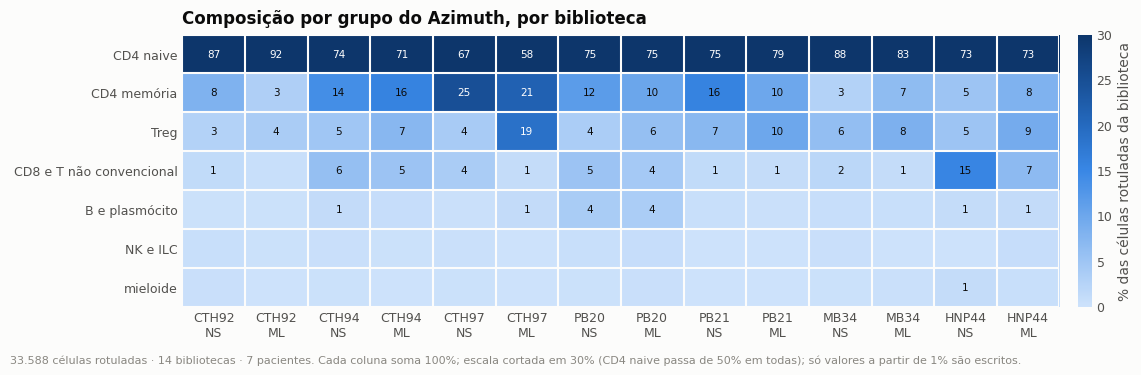

In [3]:
fig, ax = plt.subplots(figsize=(11.5, 3.6))
m = ct.div(ct.sum(axis=0), axis=1) * 100
m.columns = [f"{l.split('_')[0]}\n{l.split('_')[1]}" for l in LIBS]
plotting.heatmap(ax, m, vmin=0, vmax=30, fmt=".0f", annotate_above=1, cbar_label="% das células rotuladas da biblioteca",
                 xrotation=0)
ax.set_title("Composição por grupo do Azimuth, por biblioteca")
plotting.note(fig, f"{F.n(com.sum())} células rotuladas · {plotting.N_DESIGN}. Cada coluna soma 100%; escala cortada em 30% "
                   "(CD4 naive passa de 50% em todas); só valores a partir de 1% são escritos.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "rotulos_por_biblioteca", description="Composição por grupo do Azimuth em cada biblioteca",
                 data=ct.reset_index(), data_index=False)
plt.show()

## 2. Os métodos e as execuções

Uma *execução* é uma saída avaliada; um *ajuste* é uma rodada de um método
(o Scanorama dá duas saídas por ajuste: o embedding e a matriz corrigida).
"Harmony · 15 dims (P05)" é a integração atual: o mesmo ajuste do Harmony
escalado, mas com a vizinhança nas 15 primeiras dimensões, como no P05.

In [4]:
runs = bm.runs_table()
raw, meta = bm.collect()
faltam = [k for k in runs.index if k not in raw.index]
erros = {k: json.loads(v) for k, v in raw["erros"].items() if v and v != "{}"}
tab_runs = runs[["rotulo", "output", "escala", "uses_labels", "language"]].rename(columns={
    "rotulo": "execução", "output": "saída", "uses_labels": "usa rótulo", "language": "linguagem"})
tab_runs["ajuste (s)"] = meta["tempo_s"].reindex(runs.index)
tab_runs["info"] = meta["info"].reindex(runs.index)
io.save_table(tab_runs, NB, "execucoes", description="Execuções do benchmark: saída, escala, uso de rótulo e tempo de ajuste")
print(f"{len(raw)} de {len(runs)} execuções avaliadas" + (f"; faltam: {', '.join(faltam)}" if faltam else ""))
if erros:
    print("métricas que falharam:", erros)
tab_runs

18 de 18 execuções avaliadas


,execução,saída,escala,usa rótulo,linguagem,ajuste (s),info
key,,,,,,,
nao_integrado_esc,Não integrado,embedding,escalado,False,Python,0.268552,
nao_integrado,Não integrado,embedding,sem escala,False,Python,0.259116,
harmony_esc,Harmony,embedding,escalado,False,Python,3.583751,Converged after 4 iterations
harmony,Harmony,embedding,sem escala,False,Python,2.742568,Converged after 3 iterations
harmony_esc_15d,Harmony · 15 dims (P05),embedding,escalado,False,Python,3.583751,Converged after 4 iterations
scanorama_esc_emb,Scanorama,embedding,escalado,False,Python,122.138840,
scanorama_emb,Scanorama,embedding,sem escala,False,Python,113.410675,
scanorama_esc_genes,Scanorama,genes,escalado,False,Python,122.138840,
scanorama_genes,Scanorama,genes,sem escala,False,Python,113.410675,


## 3. Checagens

**(a)** O Harmony escalado do benchmark tem de reproduzir o do P05: mesmas
HVG, mesma lognorm, mesma PCA e o mesmo `harmonypy`.

**(b)** O kBET portado, em dados sintéticos: dois lotes sorteados da mesma
distribuição (esperado ≈ 0,95, porque o teste rejeita 5% por acaso) e dois
lotes deslocados (esperado ≈ 0).

In [5]:
main = ad.read_h5ad(io.data_path("P05_integracao", "reseq_raw_integrado", "h5ad"), backed="r")
TESTE = main.n_obs != N                 # cache de teste (subamostra): não há o que comparar com o P05
if not TESTE:
    assert (main.obs["cell_key"].astype(str).to_numpy() == obs["cell_key"].to_numpy()).all()
    harm_bench = bm.read_output("harmony_esc")["emb"]
    harm_p05 = np.asarray(main.obsm["X_emb_harmony"])
    pca_p05 = np.asarray(main.obsm["X_pca"])
    dif_pca = float(np.abs(np.abs(inp["pre_esc"].obsm["X_pca"]) - np.abs(pca_p05)).max())
    dif_harm = float(np.abs(harm_bench - harm_p05).max())
    umap_p05 = np.asarray(main.obsm["X_umap"])
    print(f"PCA: diferença máxima (em módulo) {dif_pca:.2e}; Harmony: diferença máxima {dif_harm:.2e} "
          f"(escala dos valores: {np.abs(harm_p05).max():.1f})")
else:
    dif_pca = dif_harm = np.nan
    print("cache de teste: comparação com o P05 pulada")

rng = np.random.default_rng(0)
sint = []
for nome, desloc in (("misturados", 0.0), ("deslocados", 6.0)):
    X = rng.normal(size=(1200, 10))
    centros = np.repeat([0, 8], 600)
    X[:, 0] += centros
    lote = np.tile(["a", "b"], 600)
    X[lote == "b", 1] += desloc
    a = ad.AnnData(obs=pd.DataFrame({"lote": pd.Categorical(lote), "tipo": pd.Categorical(centros.astype(str))},
                                    index=[f"c{i}" for i in range(1200)]))
    a.obsm["X_emb"] = X
    sint.append({"cenário": nome, "kBET (escalado)": bm.kbet(a, "lote", "tipo", type_="embed", embed="X_emb")})
sint = pd.DataFrame(sint).set_index("cenário")
io.save_table(sint, NB, "kbet_sintetico", description="kBET portado em dados sintéticos")
sint.round(3)

PCA: diferença máxima (em módulo) 5.96e-08; Harmony: diferença máxima 5.96e-08 (escala dos valores: 62.8)


/mnt/SATA/singleCellTaru/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,kBET (escalado)
cenário,
misturados,0.974
deslocados,0.000


## 4. As métricas brutas

Uma linha por execução, nos valores do `scib` (todos em 0–1, maior = melhor),
antes do escalonamento. "–" = a métrica não se aplica à saída, como no
artigo: as saídas de grafo (BBKNN) não têm embedding nem matriz, e a
conservação de HVG só existe para quem devolve matriz corrigida.

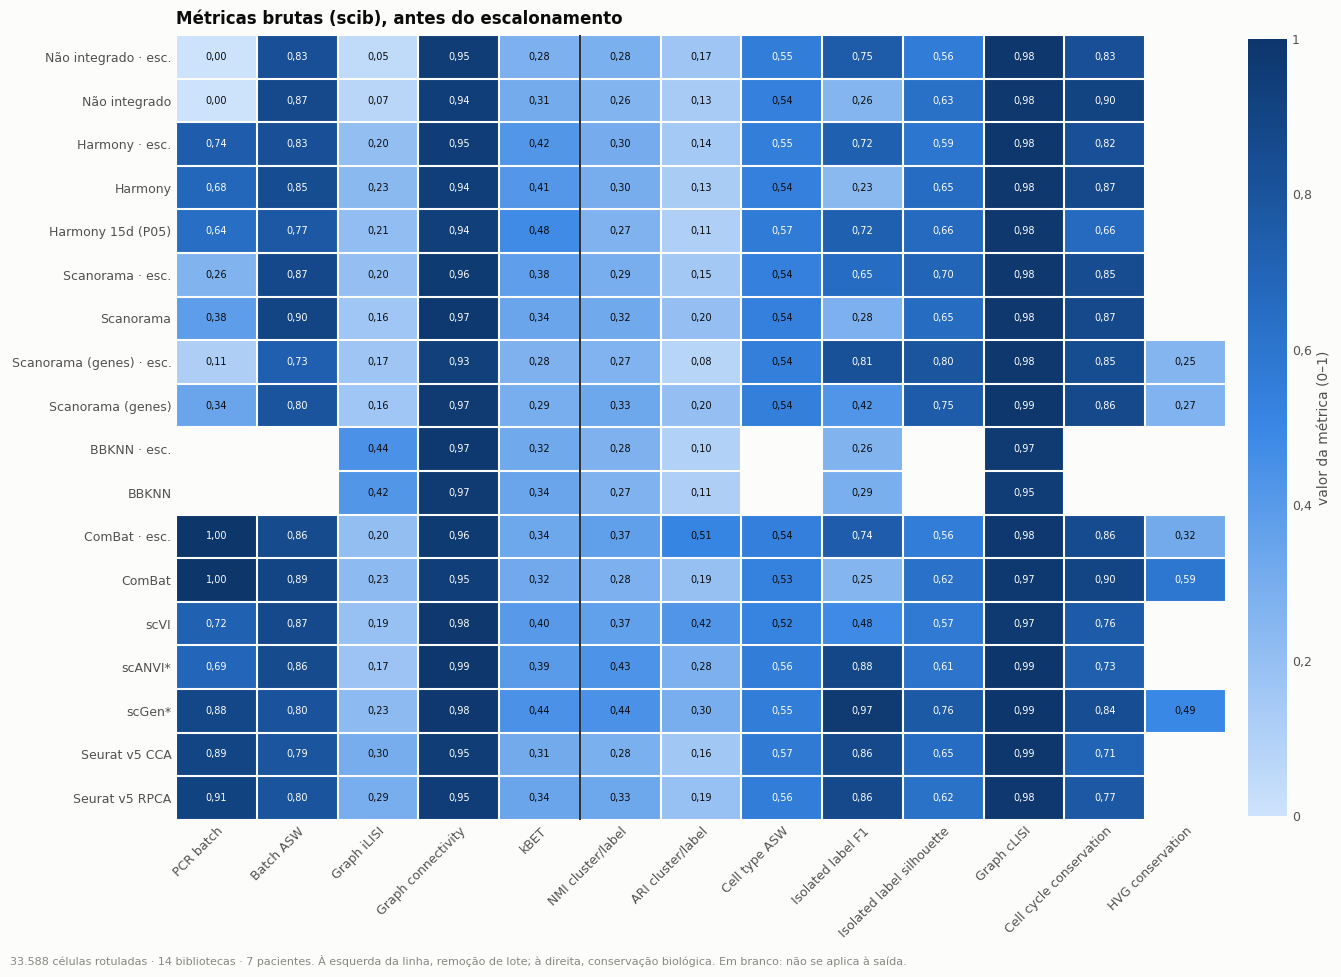

In [6]:
cols = bm.BATCH_METRICS + bm.BIO_METRICS
brutas = raw[cols].copy()
io.save_table(raw.drop(columns=["erros"]).join(runs[["rotulo", "output", "escala"]]), NB, "metricas_brutas",
              description="Métricas brutas por execução (scib; métricas do estudo; tempo das métricas)")
fig, ax = plt.subplots(figsize=(13.5, 0.4 * len(brutas) + 2.4))
m = brutas.copy()
m.index = [bp._short(k) for k in m.index]
plotting.heatmap(ax, m, vmin=0, vmax=1, fmt=".2f", cbar_label="valor da métrica (0–1)", fontsize=7)
ax.axvline(len(bm.BATCH_METRICS) - 0.5, color=INK["primary"], lw=1.2)
ax.set_title("Métricas brutas (scib), antes do escalonamento")
plotting.note(fig, f"{F.n(com.sum())} células rotuladas · {plotting.N_DESIGN}. À esquerda da linha, remoção de lote; à direita, "
                   "conservação biológica. Em branco: não se aplica à saída.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "metricas_brutas", description="Métricas brutas do scib por execução",
                 data=brutas.reset_index(), data_index=False)
plt.show()

## 5. O resultado no formato do artigo

Como nas Figs. 2a e 3b do scIB: as execuções ordenadas pelo score geral;
barras para os scores agregados; um círculo por métrica, com tamanho e cor
proporcionais ao score escalonado (min-max entre as execuções).

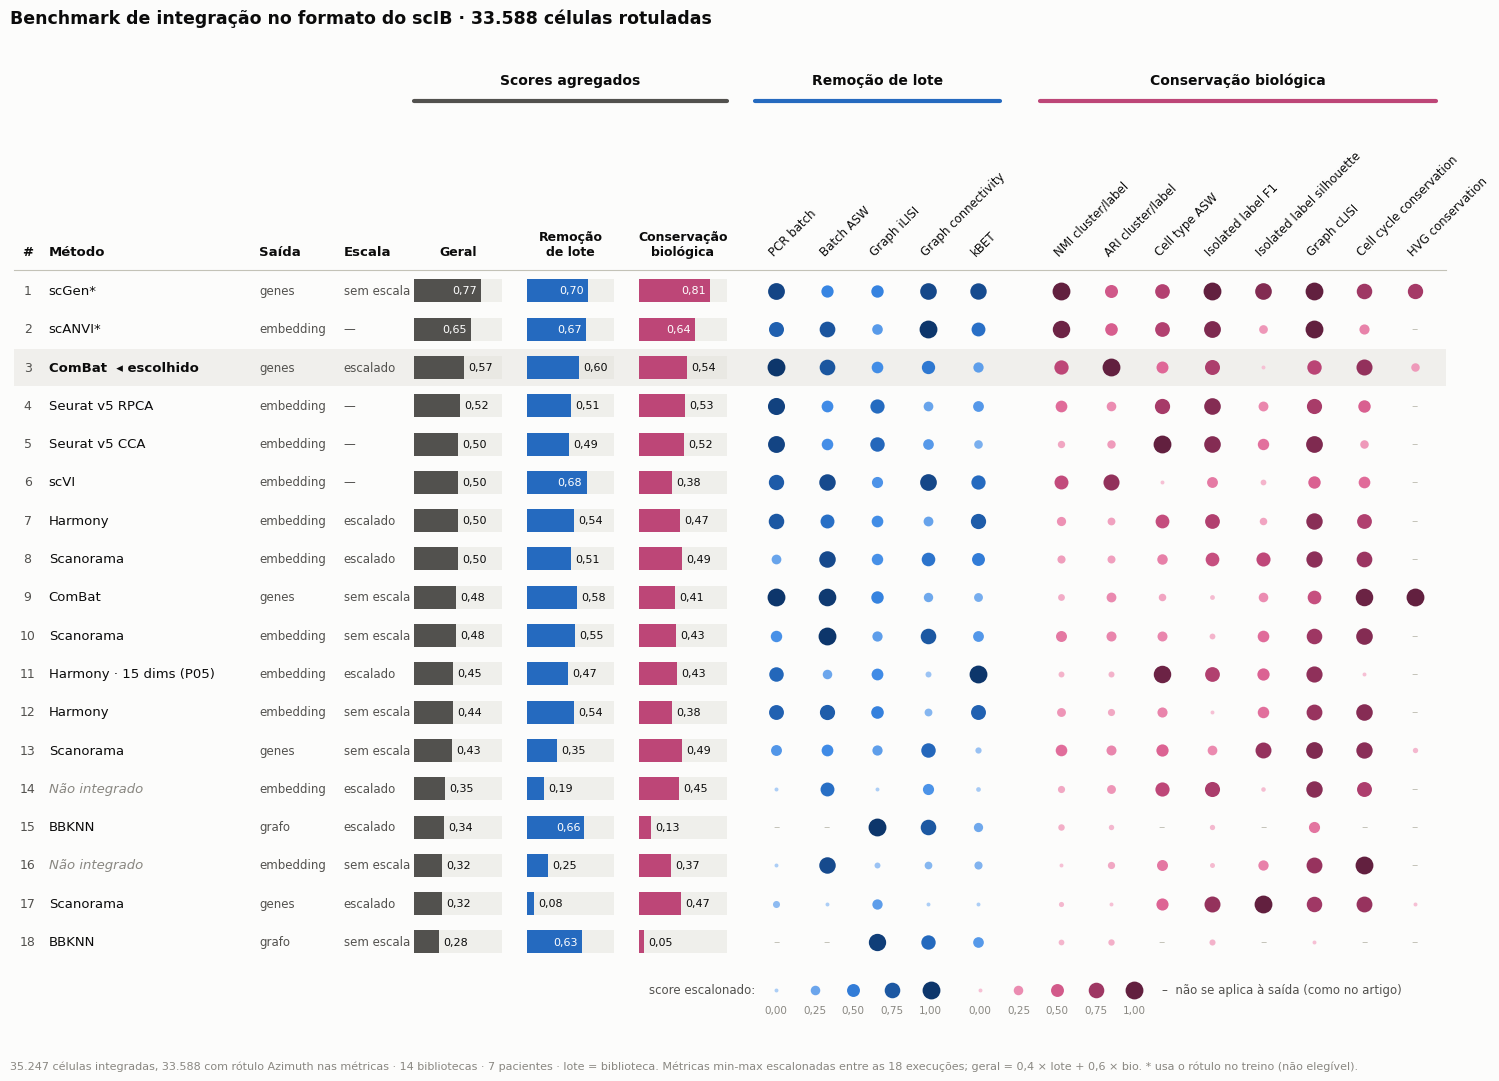

In [7]:
escal = bm.minmax(raw, cols)
resumo = bm.aggregate(raw)
ret = bm.stimulus_retention(raw)
esc = bm.choose(resumo, ret)
ESC = esc["escolhido"]
resumo_tab = resumo.join(runs[["rotulo", "output", "escala", "uses_labels"]]).join(
    ret.rename("estímulo preservado")).join(raw[["separacao_estimulo", "profundidade_vizinhanca"]])
resumo_tab = resumo_tab.sort_values("Overall score", ascending=False)
io.save_table(resumo_tab, NB, "resumo", description="Scores do artigo (min-max; 0,4 lote + 0,6 bio) e métricas do estudo")
io.save_table(escal.join(runs[["rotulo"]]), NB, "metricas_escalonadas", description="Métricas escalonadas (min-max) por execução")
fig = bp.results_table(resumo, escal, chosen=ESC,
                       title=f"Benchmark de integração no formato do scIB · {F.n(com.sum())} células rotuladas",
                       note=f"{F.n(N)} células integradas, {F.n(com.sum())} com rótulo Azimuth nas métricas · "
                            f"{plotting.N_DESIGN} · lote = biblioteca. Métricas min-max escalonadas entre as {len(resumo)} "
                            "execuções; geral = 0,4 × lote + 0,6 × bio. * usa o rótulo no treino (não elegível).")
plotting.savefig(fig, NB, "tabela_resumo", description="Tabela-resumo do benchmark no formato do scIB (Figs. 2a e 3b)",
                 data=resumo_tab.join(escal).reset_index(), data_index=False)
plt.show()

## 6. Remoção de lote × conservação biológica

Como na Fig. 3a e na Extended Data Fig. 4 do artigo: cada ponto é uma
execução; o ideal é o canto superior direito. Linhas tracejadas = não
integrado (escalado); linhas cheias = mediana das execuções.

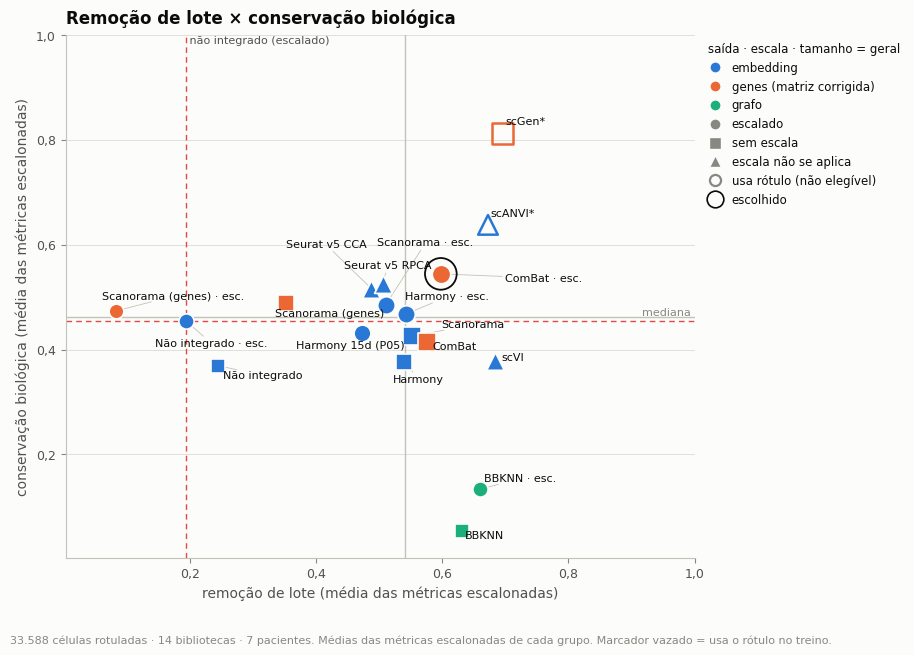

In [8]:
fig = bp.batch_bio_scatter(resumo, chosen=ESC, title="Remoção de lote × conservação biológica",
                           note=f"{F.n(com.sum())} células rotuladas · {plotting.N_DESIGN}. Médias das métricas escalonadas "
                                "de cada grupo. Marcador vazado = usa o rótulo no treino.")
plotting.savefig(fig, NB, "lote_x_bio", description="Remoção de lote × conservação biológica por execução (Fig. 3a)",
                 data=resumo_tab.reset_index(), data_index=False)
plt.show()

## 7. UMAPs

Como na Fig. 2b–c do artigo: o não integrado e os melhores métodos
elegíveis (a melhor execução de cada um). Linha 1: o rótulo Azimuth (três
grupos principais em cor). Linha 2: o estímulo. Linha 3: a mistura local de
bibliotecas — o iLISI de cada célula no grafo de 15 vizinhos (1 = vizinhos
de uma biblioteca só).

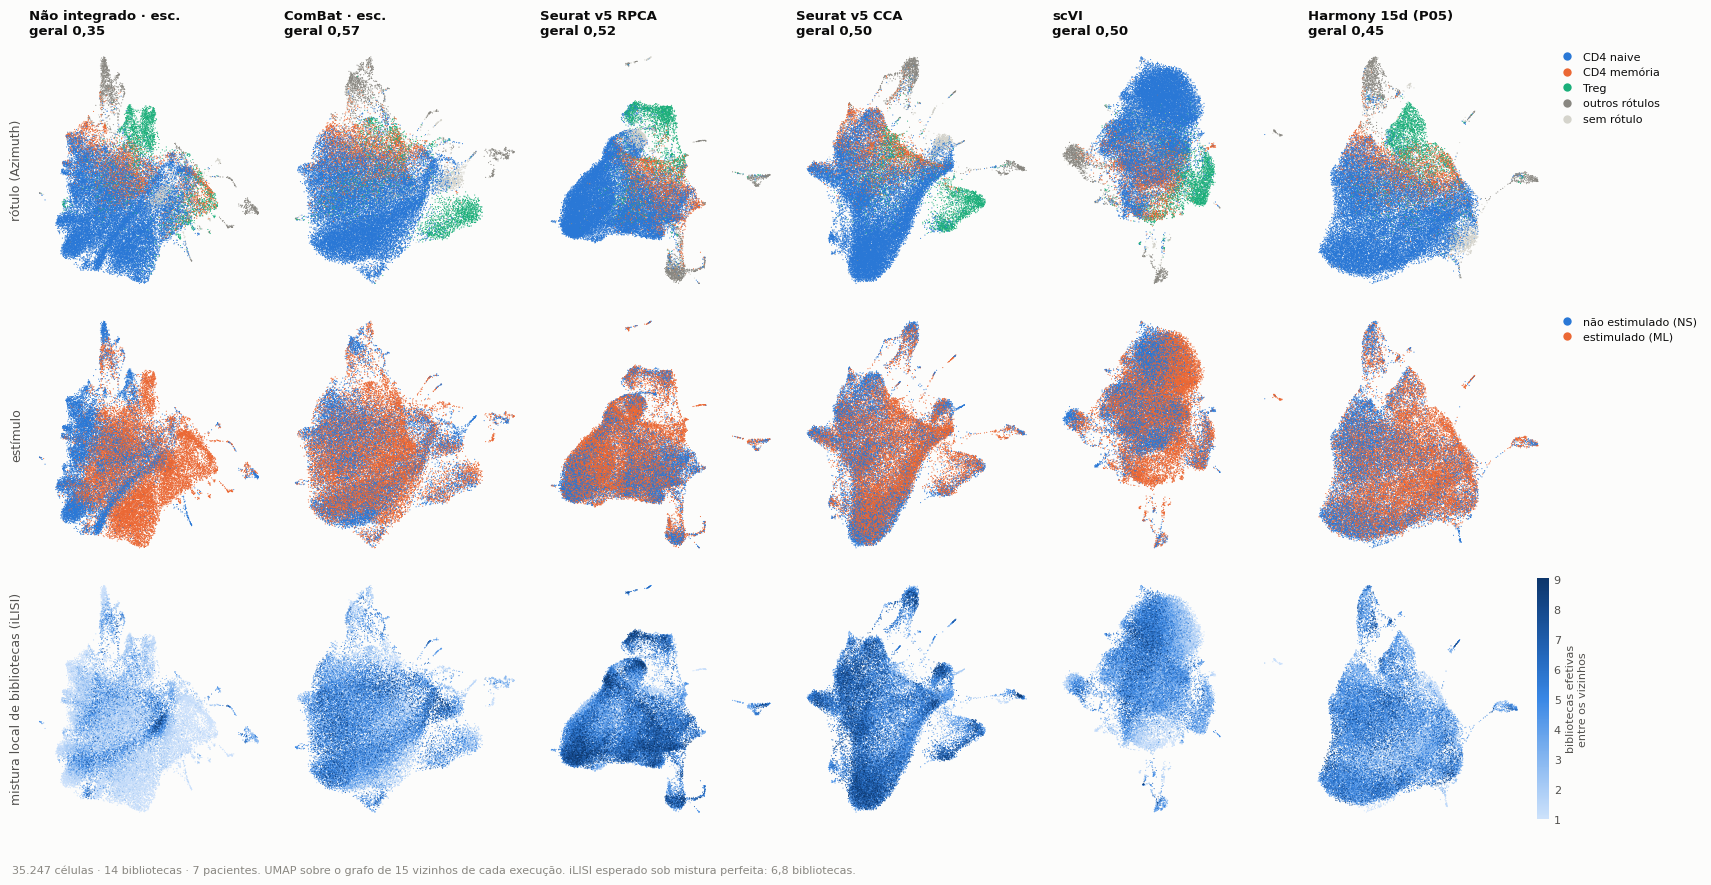

In [9]:
eleg = [k for k in resumo.sort_values("Overall score", ascending=False).index
        if not bm.RUN[k].uses_labels and not bm.RUN[k].method.startswith("Não integrado")]
melhores, vistos = [], set()
for k in eleg:
    if bm.RUN[k].method not in vistos:
        melhores.append(k)
        vistos.add(bm.RUN[k].method)
cols_umap = [bm.REFERENCE] + melhores[:4]
for extra in (bm.CURRENT, ESC):
    if extra not in cols_umap:
        cols_umap.append(extra)
lib_arr = obs[bm.BATCH].astype(str).to_numpy()
umaps, ilisi = {}, {}
for k in cols_umap:
    umaps[k] = np.load(bm.run_dir(k) / "umap.npy")
    G = sp.load_npz(bm.run_dir(k) / "grafo15_conn.npz")
    ilisi[k] = pl.knn_library_mixing(G, lib_arr)["ilisi"].to_numpy()
titulos = {k: bp._short(k) + (f"\ngeral {F.f(resumo.loc[k, 'Overall score'], 2)}") for k in cols_umap}
fig = bp.umap_grid(umaps, cols_umap, obs, ilisi, titles=titulos,
                   note=f"{F.n(N)} células · {plotting.N_DESIGN}. UMAP sobre o grafo de 15 vizinhos de cada execução. "
                        f"iLISI esperado sob mistura perfeita: {F.f(pl.expected_ilisi(lib_arr), 1)} bibliotecas.")
plotting.savefig(fig, NB, "umaps", description="UMAPs do não integrado e dos melhores métodos (Fig. 2b–c)",
                 data=pd.DataFrame({k: [float(np.median(v))] for k, v in ilisi.items()}, index=["iLISI mediano"]).T
                 .rename_axis("execucao").reset_index(), data_index=False)
plt.show()

## 8. O que o score do artigo não vê: estímulo e profundidade

**Estímulo preservado.** Em cada execução, a separação entre as duas
bibliotecas de cada paciente no grafo de 15 vizinhos (0 = misturadas,
1 = separadas; `pipeline.within_patient_separation`), dividida pela do não
integrado escalado. Parte da separação do não integrado é técnica (canal),
então 100% não é o alvo; o que interessa é quanto cada método apaga em
relação aos outros. A faixa cinza é o veto da regra de escolha.

**Profundidade na vizinhança.** ρ de Spearman entre a profundidade de cada
célula (log10 de UMIs, centrada na biblioteca) e a média dos seus vizinhos:
quanto o grafo se organiza por profundidade. Menor = melhor.

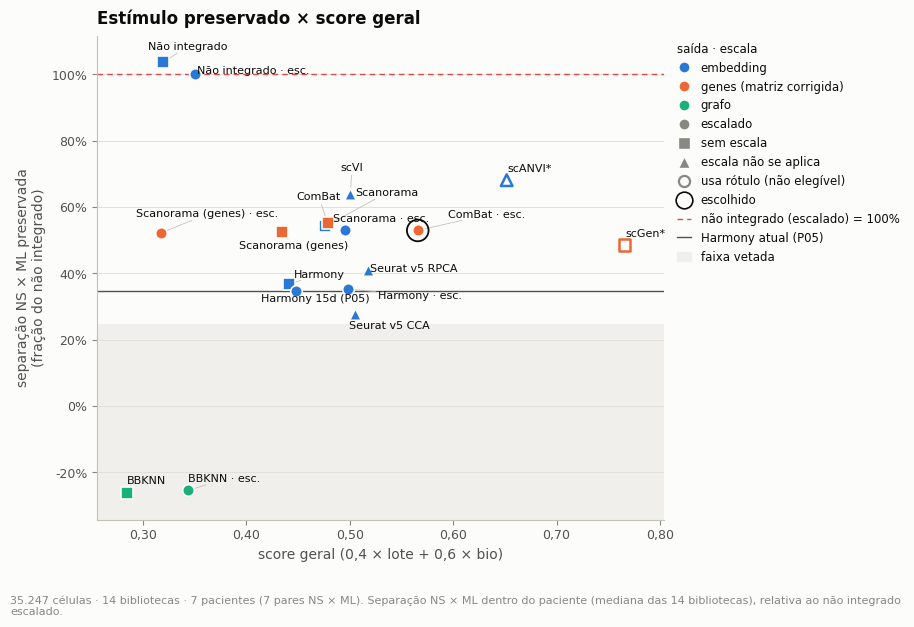

,rotulo,Overall score,separacao_estimulo,estímulo preservado,profundidade_vizinhanca
key,,,,,
scgen,scGen*,0.766,0.301,0.486,0.695
scanvi,scANVI*,0.652,0.422,0.681,0.633
combat_esc,ComBat,0.566,0.328,0.530,0.738
seurat_rpca,Seurat v5 RPCA,0.518,0.255,0.411,0.697
seurat_cca,Seurat v5 CCA,0.505,0.172,0.277,0.663
scvi,scVI,0.501,0.397,0.640,0.544
harmony_esc,Harmony,0.498,0.219,0.354,0.714
scanorama_esc_emb,Scanorama,0.496,0.328,0.530,0.707
combat,ComBat,0.479,0.342,0.552,0.621


In [10]:
fig = bp.stimulus_scatter(resumo, ret, chosen=ESC, floor=esc["piso_estimulo"],
                          title="Estímulo preservado × score geral",
                          note=f"{F.n(N)} células · {plotting.N_DESIGN} (7 pares NS × ML). Separação NS × ML dentro do paciente "
                               "(mediana das 14 bibliotecas), relativa ao não integrado escalado.")
plotting.savefig(fig, NB, "estimulo_x_geral", description="Separação NS × ML preservada × score geral",
                 data=resumo_tab[["rotulo", "Overall score", "estímulo preservado", "separacao_estimulo"]].reset_index(),
                 data_index=False)
plt.show()
estudo = resumo_tab[["rotulo", "Overall score", "separacao_estimulo", "estímulo preservado", "profundidade_vizinhanca"]]
estudo.round(3)

## 9. Robustez da classificação

O artigo checou que a classificação não dependia do escalonamento (z-score no
lugar do min-max, Spearman > 0,96). Aqui, além disso: pesos iguais para lote
e bio; métricas sem escalonamento; o min-max refeito só entre as execuções
elegíveis e o não integrado (o escalonamento depende de quem está na
comparação); e sem as duas métricas de rótulo isolado, que aqui medem um
grupo só (mieloide, ~40 células) e oscilam muito entre execuções.
Posição entre os elegíveis, 1 = melhor.

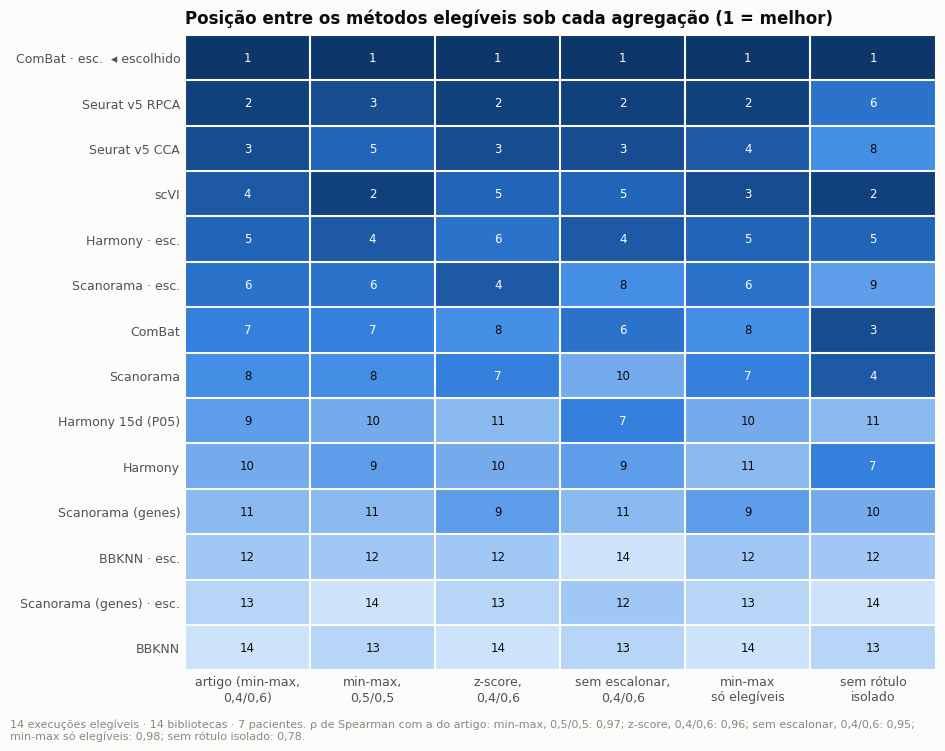

In [11]:
variantes = {
    "artigo (min-max, 0,4/0,6)": bm.aggregate(raw),
    "min-max, 0,5/0,5": bm.aggregate(raw, w_batch=0.5),
    "z-score, 0,4/0,6": bm.aggregate(raw, scaling="zscore"),
    "sem escalonar, 0,4/0,6": bm.aggregate(raw, scaling="none"),
    "min-max só elegíveis": bm.aggregate(raw.loc[[k for k in raw.index if not bm.RUN[k].uses_labels]]),
    "sem rótulo isolado": bm.aggregate(raw, drop=("Isolated label F1", "Isolated label silhouette")),
}
pos = pd.DataFrame({n: v.loc[eleg, "Overall score"].rank(ascending=False, method="min") for n, v in variantes.items()})
pos = pos.loc[pos.iloc[:, 0].sort_values().index]
rho_var = {n: float(stats.spearmanr(pos.iloc[:, 0], pos[n]).statistic) for n in pos.columns[1:]}
io.save_table(pos.join(runs[["rotulo"]]), NB, "robustez", description="Posição dos elegíveis sob variações da agregação")
fig, ax = plt.subplots(figsize=(9.5, 0.36 * len(pos) + 2.2))
m = len(pos) + 1 - pos                      # cor: mais escuro = melhor posição; o texto mostra a posição
m.index = [bp._short(k) + ("  ◂ escolhido" if k == ESC else "") for k in m.index]
m.columns = [c.replace(", ", ",\n").replace(" só ", "\nsó ").replace("sem rótulo ", "sem rótulo\n") for c in m.columns]
plotting.heatmap(ax, m, vmin=1, vmax=len(pos), cbar=False, xrotation=0)
for i in range(pos.shape[0]):
    for j in range(pos.shape[1]):
        ax.text(j, i, str(int(pos.iat[i, j])), ha="center", va="center", fontsize=8.5,
                color="white" if m.iat[i, j] / len(pos) > 0.55 else INK["primary"])
ax.set_title("Posição entre os métodos elegíveis sob cada agregação (1 = melhor)")
plotting.note(fig, f"{len(pos)} execuções elegíveis · {plotting.N_DESIGN}. ρ de Spearman com a do artigo: "
                   + "; ".join(f"{n}: {F.f(v, 2)}" for n, v in rho_var.items()) + ".", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "robustez", description="Posição dos elegíveis sob variações da agregação",
                 data=pos.reset_index(), data_index=False)
plt.show()

## 10. Tempo e memória

Como na Extended Data Fig. 7: o tempo de cada ajuste (só o método, sem ler
os dados nem calcular as métricas) e a memória de pico além da base do
processo (inclui o R, para o Seurat). Uma máquina: 12 CPUs, 31 GB, RTX 3060 Ti.

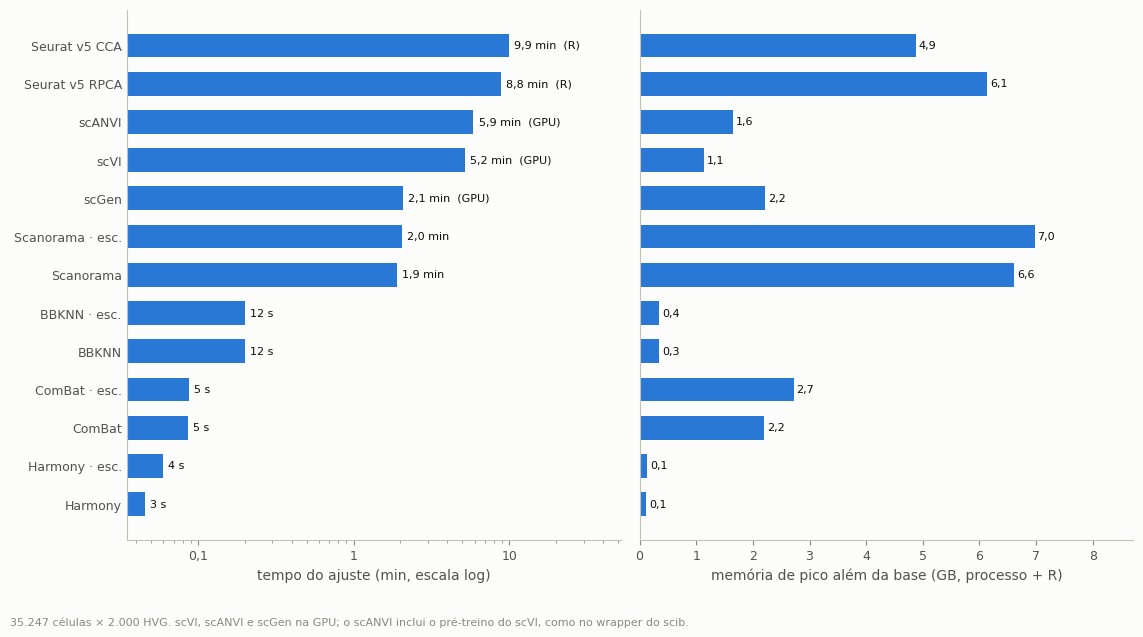

In [12]:
fig = bp.runtime_bars(meta.reset_index(), note=f"{F.n(N)} células × {F.n(pre.n_vars)} HVG. scVI, scANVI e scGen na GPU; "
                                                "o scANVI inclui o pré-treino do scVI, como no wrapper do scib.")
plotting.savefig(fig, NB, "tempo_memoria", description="Tempo e memória de pico por ajuste (Extended Data Fig. 7)",
                 data=meta.drop_duplicates("ajuste")[["ajuste", "tempo_s", "memoria_pico_gb"]].reset_index(),
                 data_index=False)
plt.show()

## 11. A escolha e a justificativa

In [13]:
r_esc = resumo.loc[ESC]
pos_esc = int(pos.loc[ESC].iloc[0])
top = esc["melhor_geral_elegivel"]
lin = []
lin.append(f"**{bp._short(ESC)}**: score geral {F.f(r_esc['Overall score'], 3)} "
           f"(lote {F.f(r_esc['Batch correction'], 3)}, bio {F.f(r_esc['Bio conservation'], 3)}), "
           f"{pos_esc}ª entre {len(eleg)} execuções elegíveis.")
if top != ESC:
    lin.append(f"O maior score geral elegível é de {bp._short(top)} ({F.f(resumo.loc[top, 'Overall score'], 3)}); "
               f"{'foi vetado pelo estímulo' if top in esc['vetados'] else 'empatou (diferença < 0,02) e preserva menos estímulo'}.")
lin.append(f"Empatados (a menos de {F.f(esc['tolerancia_empate'], 2)} do melhor): "
           + ", ".join(f"{bp._short(k)} ({F.f(resumo.loc[k, 'Overall score'], 3)}; estímulo {F.pct(ret[k], 0)})"
                       for k in esc["empatados"]) + ".")
lin.append("Vetados pelo estímulo (preservam menos de " + F.pct(esc["piso_estimulo"], 0) + " da separação do não integrado): "
           + (", ".join(f"{bp._short(k)} ({F.pct(ret[k], 0)})" for k in esc["vetados"]) or "nenhum") + ".")
lin.append(f"Estímulo preservado: {F.pct(ret[ESC], 0)} (Harmony atual: {F.pct(ret[bm.CURRENT], 0)}).")
lin.append("Posição sob as outras agregações: " + "; ".join(f"{c} → {int(pos.loc[ESC, c])}ª" for c in pos.columns) + ".")
if ESC in meta.index:
    lin.append(f"Ajuste em {F.f(meta.loc[ESC, 'tempo_s'] / 60, 1)} min.")
justificativa = "\n".join(f"* {t}" for t in lin)
from IPython.display import Markdown
display(Markdown(justificativa))
io.save_table(pd.DataFrame({"item": lin}), NB, "justificativa", description="Justificativa da escolha do método de integração",
              index=False)
(bm.CACHE / "escolha.json").write_text(json.dumps({**esc, "assinatura": inp["assinatura"]}, ensure_ascii=False, indent=1))

* **ComBat · esc.**: score geral 0,566 (lote 0,598, bio 0,544), 1ª entre 14 execuções elegíveis.
* Empatados (a menos de 0,02 do melhor): ComBat · esc. (0,566; estímulo 53%).
* Vetados pelo estímulo (preservam menos de 25% da separação do não integrado): BBKNN · esc. (-25%), BBKNN (-26%).
* Estímulo preservado: 53% (Harmony atual: 35%).
* Posição sob as outras agregações: artigo (min-max, 0,4/0,6) → 1ª; min-max, 0,5/0,5 → 1ª; z-score, 0,4/0,6 → 1ª; sem escalonar, 0,4/0,6 → 1ª; min-max só elegíveis → 1ª; sem rótulo isolado → 1ª.
* Ajuste em 0,1 min.

300

A integração escolhida vai para `dataReseq/` como um objeto pequeno (delta,
sem a matriz): `cell_key`, o embedding (ou a PCA da matriz corrigida), o
grafo de 15 vizinhos e a UMAP. O P08 o une ao objeto principal.

In [14]:
run_esc = bm.RUN[ESC]
delta = ad.AnnData(X=sp.csr_matrix((N, 0), dtype=np.float32),       # sem genes: só a integração
                   obs=pd.DataFrame({"cell_key": obs["cell_key"].to_numpy(), bm.BATCH: lib_arr}, index=obs.index))
saida = bm.read_output(ESC)
if run_esc.output == "embedding":
    delta.obsm["X_emb"] = saida["emb"]
elif run_esc.output == "genes":
    tmp = ad.AnnData(X=saida["X"])
    sc.tl.pca(tmp, n_comps=config.N_PCS, random_state=config.RANDOM_STATE)
    delta.obsm["X_emb"] = tmp.obsm["X_pca"].astype(np.float32)
delta.obsp["connectivities"] = sp.load_npz(bm.run_dir(ESC) / "grafo15_conn.npz")
delta.obsp["distances"] = sp.load_npz(bm.run_dir(ESC) / "grafo15_dist.npz")
delta.obsm["X_umap"] = np.load(bm.run_dir(ESC) / "umap.npy")
delta.uns["integracao"] = {"execucao": ESC, "metodo": run_esc.label, "saida": run_esc.output, "escala": run_esc.scaling,
                           "score_geral": float(r_esc["Overall score"]), "estimulo_preservado": float(ret[ESC]),
                           "assinatura_entradas": inp["assinatura"]}
io.save_data(delta, NB, "integracao_escolhida",
             description=f"Integração escolhida pelo benchmark ({run_esc.label}): embedding, grafo de 15 vizinhos e UMAP; "
                         "chave cell_key")
io.save_data(resumo_tab.join(raw[cols]).reset_index(), NB, "benchmark",
             description="Scores e métricas do benchmark de integração por execução")
igual_p05 = ESC == bm.CURRENT
print(f"escolhido: {run_esc.label} ({ESC}); igual à integração do P05: {igual_p05}")
if igual_p05 and not TESTE:
    g05 = main.obsp["connectivities"]
    print(f"grafo idêntico ao do P05: {(abs(delta.obsp['connectivities'] - g05) > 1e-6).nnz == 0}; "
          f"UMAP idêntica: {np.allclose(delta.obsm['X_umap'], umap_p05)}")

[io] inalterado, não regravado: integracao_escolhida.h5ad
[io] inalterado, não regravado: benchmark.parquet
escolhido: ComBat (combat_esc); igual à integração do P05: False


## Problemas encontrados

In [15]:
log.add("INFO", "reprodução do P05", "[VERIFICAÇÃO] o Harmony escalado do benchmark reproduz o do P05",
        evidence=f"diferença máxima: PCA {dif_pca:.1e}, Harmony {dif_harm:.1e}",
        impact="as métricas da linha 'Harmony · 15 dims (P05)' são as da integração em uso",
        recommendation="nenhuma")
log.add("INFO", "kBET portado", "[VERIFICAÇÃO] o porte do kBET separa lotes misturados de deslocados",
        evidence="; ".join(f"{i}: {F.f(v, 2)}" for i, v in sint["kBET (escalado)"].items()),
        impact="o kBET entra no score de remoção de lote como no artigo, sem rpy2",
        recommendation="nenhuma")
log.add("MINOR", "rótulo das métricas biológicas",
        "não há anotação curada; as métricas biológicas usam o Azimuth automático do Cell Ranger",
        evidence=f"{F.pct(com.mean(), 1)} das células com rótulo; CD4 naive = "
                 f"{F.pct(por_grupo.loc['CD4 naive', '% das rotuladas'], 0)} das rotuladas",
        impact="as métricas premiam conservar a divisão naive / memória / Treg / não-T, não estados finos de ativação",
        recommendation="refazer o benchmark com a anotação final, se ela mudar muito em relação ao Azimuth")
if not isolados:
    log.add("MINOR", "isolated labels", "todos os grupos aparecem em todas as bibliotecas; o scib não acha rótulo isolado",
            evidence="bibliotecas por grupo: " + ", ".join(f"{g} {n}" for g, n in por_grupo["bibliotecas com o rótulo"].items()),
            impact="isolated label F1 e silhouette ficam sem valor e não entram na média bio",
            recommendation="nenhuma")
log.add("MAJOR" if ret[ESC] < 0.5 else "MINOR", "integração × estímulo",
        "toda correção por biblioteca aproxima as duas bibliotecas de cada paciente (estímulo e canal confundidos)",
        evidence=f"separação NS × ML preservada: escolhido {F.pct(ret[ESC], 0)}; faixa entre os elegíveis "
                 f"{F.pct(ret[eleg].min(), 0)}–{F.pct(ret[eleg].max(), 0)}",
        impact="o efeito do estímulo fica atenuado no espaço integrado e nos clusters",
        recommendation="testar o estímulo por pseudobulk pareado nas contagens, não pela composição dos clusters")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       0
MINOR       2
INFO        2


severity,location,problem,evidence,impact,recommendation
MINOR,rótulo das métricas biológicas,não há anotação curada; as métricas biológicas usam o Azimuth automático do Cell Ranger,"95,3% das células com rótulo; CD4 naive = 75% das rotuladas","as métricas premiam conservar a divisão naive / memória / Treg / não-T, não estados finos de ativação","refazer o benchmark com a anotação final, se ela mudar muito em relação ao Azimuth"
MINOR,integração × estímulo,toda correção por biblioteca aproxima as duas bibliotecas de cada paciente (estímulo e canal confundidos),separação NS × ML preservada: escolhido 53%; faixa entre os elegíveis -26%–64%,o efeito do estímulo fica atenuado no espaço integrado e nos clusters,"testar o estímulo por pseudobulk pareado nas contagens, não pela composição dos clusters"
INFO,reprodução do P05,[VERIFICAÇÃO] o Harmony escalado do benchmark reproduz o do P05,"diferença máxima: PCA 6.0e-08, Harmony 6.0e-08",as métricas da linha 'Harmony · 15 dims (P05)' são as da integração em uso,nenhuma
INFO,kBET portado,[VERIFICAÇÃO] o porte do kBET separa lotes misturados de deslocados,"misturados: 0,97; deslocados: 0,00","o kBET entra no score de remoção de lote como no artigo, sem rpy2",nenhuma


## Conclusão

**Escolha: ComBat sobre a lognorm escalonada** (matriz corrigida; a
vizinhança e a UMAP saem da PCA dessa matriz). Entre as 14 execuções
elegíveis, teve o maior score geral (0,566: lote 0,598, bio 0,544), sem
empate (o 2º, Seurat RPCA, tem 0,518), e ficou em 1º sob as seis formas de
agregar. Acima dele só ficaram scGen\* (0,766) e scANVI\* (0,652), que usam o
rótulo Azimuth no treino e por isso não eram elegíveis.

**Por que ele vence.** Remove toda a variância da PCA explicada pela
biblioteca (PCR batch 1,00) e conserva a estrutura do rótulo melhor que os
outros sem rótulo: maior ARI de todas as execuções (0,51), NMI 0,37, ciclo
celular 0,86, isolated label F1 0,74. A mistura local é mais modesta (kBET
0,34, iLISI 0,20), mas a mistura extrema só veio junto com perda de biologia:
o BBKNN mistura mais que todos e fica com a pior conservação biológica. Isso
é coerente com o artigo, que cita benchmarks anteriores em tarefas simples
em que o ComBat ou o Harmony superavam os métodos não lineares, e que viu o
ComBat conservar bem a variância de ciclo celular e ir melhor com HVG. Aqui a
tarefa é simples: um tipo celular separado por citometria (CD4⁺) em 14
bibliotecas de composição parecida, em que o efeito de lote é sobretudo um
deslocamento por gene, que é o que o ComBat modela.

**Estímulo.** O ComBat preserva 53% da separação NS × ML do não integrado,
contra 35% do Harmony atual. Os dois BBKNN foram vetados: a separação dentro
do paciente fica negativa (o BBKNN força 3 vizinhos de cada biblioteca, e
as duas bibliotecas do paciente ficam mais misturadas que o acaso).

**A integração do P05** (Harmony, vizinhança em 15 dimensões) ficou em 9º
entre 14 (0,448). Com as 50 dimensões, o Harmony escalado sobe para 5º
(0,498). Ela não estava errada, mas é dominada pelo ComBat em lote, em bio e
em estímulo preservado.

**Limites.** Um conjunto de dados só, sem barras de erro entre tarefas; o
rótulo é o Azimuth automático, dominado por CD4 naive (75%); o rótulo
isolado é um grupo de 42 células (mieloide), e sem as duas métricas dele a
classificação dos outros muda (ρ = 0,78), mas o ComBat continua em 1º. A
profundidade organiza a vizinhança do ComBat tanto quanto a do Harmony (ρ
0,74 e 0,71): os clusters técnicos de baixa profundidade devem continuar
aparecendo no P08. Para expressão diferencial, a matriz corrigida não serve:
usar as contagens.

Saídas: `dataReseq/P07_benchmark_integracao/integracao_escolhida.h5ad`
(embedding, grafo e UMAP do ComBat; chave `cell_key`) e `benchmark.parquet`
(scores e métricas). O P08 clusteriza sobre essa integração.

In [16]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook (fora os caches de cada execução):")
print(feitos[feitos["kind"] != "cache"].to_string(index=False))

48 artefatos gravados por este notebook (fora os caches de cada execução):
                      name    kind
      integracao_escolhida    h5ad
                 benchmark parquet
                   rotulos   table
    rotulos_por_biblioteca   table
              rotulos_fora   table
fig_rotulos_por_biblioteca  figure
fig_rotulos_por_biblioteca   table
                 execucoes   table
            kbet_sintetico   table
           metricas_brutas   table
       fig_metricas_brutas  figure
       fig_metricas_brutas   table
                    resumo   table
      metricas_escalonadas   table
         fig_tabela_resumo  figure
         fig_tabela_resumo   table
            fig_lote_x_bio  figure
            fig_lote_x_bio   table
                 fig_umaps  figure
                 fig_umaps   table
      fig_estimulo_x_geral  figure
      fig_estimulo_x_geral   table
                  robustez   table
              fig_robustez  figure
              fig_robustez   table
         fig_te